In [1]:
%pip install torch
%pip install matplotlib
%pip install scikit-learn
%pip install numpy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:

import torch

In [3]:

from sklearn.datasets import make_regression
import matplotlib.pyplot as plt

bias = 0
num_features = 1
X_numpy, y_numpy, coef = make_regression(
    n_samples=5000,
    n_features=num_features,
    n_targets=1,
    noise=5,
    bias=bias,
    coef=True,
    random_state=42
)

## Solving the least squares problem via gradient descent

Suppose we are given $\mathbf{A} \in \mathbb{R}^{m \times n}$ and $\mathbf{b} \in \mathbb{R}^{m \times 1}$ and we want to find the vector $\boldsymbol{x} \in \mathbb{R}^{n \times 1}$ that minimizes $f(\boldsymbol{x})$:

$$
    f(\boldsymbol{x}) = \frac{1}{2} \| \mathbf{A}\boldsymbol{x} -b \|_2^2
$$

Note that if we set $\mathbf{A}$ to be an encoding of a training set, $\mathbf{b}$ to be an encoding of the target value, then $\boldsymbol{x}$ can be thought of as the parameters of a linear model that approximates the target value.

There are specialized linear algebra algorithms that can solve this problem efficiently. However, we can also explore how to solve it using gradient-based optimization as a simple example of how these techniques work.

The gradient of $f$ is:

$$
    \nabla f(\boldsymbol{x}) = \mathbf{A}^\top (\mathbf{A} \boldsymbol{x} - \mathbf{b}) = \mathbf{A}^\top \mathbf{A} \boldsymbol{x} - \mathbf{A}^\top \mathbf{b}
$$

To see why this is so, it is better to think to $\| \boldsymbol{v} \|^2_2 = \boldsymbol{v}^\top \boldsymbol{v}$, yielding:

$$
\begin{aligned}
    \frac{1}{2} \| \mathbf{A}\boldsymbol{x} - \mathbf{b} \|^2_2
        & = \frac{1}{2} (\mathbf{A}\boldsymbol{x} - \mathbf{b})^\top (\mathbf{A}\boldsymbol{x} - \mathbf{b}) \\
        & = \frac{1}{2} (\boldsymbol{x}^\top \mathbf{A}^\top - \mathbf{b}^T)(\mathbf{A}\boldsymbol{x} - \mathbf{b}) \\
        & = \frac{1}{2} (\boldsymbol{x}^\top \mathbf{A}^\top \mathbf{A}\boldsymbol{x}  - \boldsymbol{x}^\top \mathbf{A}^\top \mathbf{b} - \mathbf{b}^T \mathbf{A}\boldsymbol{x} + \mathbf{b}^T \mathbf{b})
\end{aligned}
$$

<!-- what we need:
    - (AB).T = B.T A.T
    - \| v \|^2 = v.T v
-->

we have then:

$$
\begin{aligned}
    \nabla_{\boldsymbol{x}} f(\boldsymbol{x}) & = \nabla_{\boldsymbol{x}} \frac{1}{2} (\boldsymbol{x}^\top \mathbf{A}^\top \mathbf{A}\boldsymbol{x}  - \boldsymbol{x}^\top \mathbf{A}^\top \mathbf{b} - \mathbf{b}^T \mathbf{A}\boldsymbol{x} + \mathbf{b}^T \mathbf{b}) \\
    & = \frac{1}{2} (\nabla_{\boldsymbol{x}} \boldsymbol{x}^\top \mathbf{A}^\top \mathbf{A}\boldsymbol{x}  - \nabla_{\boldsymbol{x}} \boldsymbol{x}^\top \mathbf{A}^\top \mathbf{b} - \nabla_{\boldsymbol{x}} \mathbf{b}^T \mathbf{A}\boldsymbol{x} + \nabla_{\boldsymbol{x}} \mathbf{b}^T \mathbf{b}) \\
    & = \frac{1}{2} (2 \mathbf{A}^\top \mathbf{A} \boldsymbol{x} - \mathbf{A}^\top \mathbf{b} - \mathbf{A}^T \mathbf{b}) \\
    & = \frac{1}{2} (2 \mathbf{A}^\top \mathbf{A} \boldsymbol{x} - 2 \mathbf{A}^\top \mathbf{b}) \\
    & = \mathbf{A}^\top \mathbf{A} \boldsymbol{x} - \mathbf{A}^\top \mathbf{b}
\end{aligned}
$$

where we used the following identities:

$$
\begin{aligned}
    \nabla_{\boldsymbol{x}} \boldsymbol{x}^\top \mathbf{Z} \boldsymbol{x} & = 2 \mathbf{Z} \boldsymbol{x}, & \text{which holds if $\mathbf{Z}$ is symmetric and not a function of $\boldsymbol{x}$}; \\
    \nabla_{\boldsymbol{x}} \mathbf{a}^\top  \boldsymbol{x} = \nabla_{\boldsymbol{x}} \boldsymbol{x}^T \mathbf{a} & = \mathbf{a}, & \text{which holds if $\mathbf{a}$ is not a function of $\boldsymbol{x}$}.

\end{aligned}
$$

For an introduction to differentiation in matrix form, see https://atmos.uw.edu/~dennis/MatrixCalculus.pdf

We can then follow the gradient downhill taking small steps by iteratively update $\boldsymbol{x}$ using the rule $\boldsymbol{x} \leftarrow \boldsymbol{x} - \epsilon \nabla_{\boldsymbol{x}} f(\boldsymbol{x})$ until convergence. Let's implement this.

In [4]:
def f(A,b,x):
    """
    Computes f(x) = 1/2 * ||Ax - b||^2.
    """
    return 0.5 * torch.norm(A @ x - b)**2


def grad_f(A,b,x):
    """
    Computes the gradient di f(x) = 0.5 ||Ax-b|| as: AT Ax - AT b
    """
    return A.T @ A @ x - A.T @ b

def minimize_f(A, b, eps, delta):
    """
    Minimize f(x) = 1/2 * ||Ax - b||^2 using gradient descent.
    """

    x = torch.rand(A.shape[1], dtype=torch.float64)  # inizializza x casualmente, shape[1] = numero di features (colonne di A)
    g = grad_f(A, b, x) # calcola il gradiente iniziale

    while torch.norm(g) > delta: # continua fino a quando la norma del gradiente è maggiore di delta, cioè fino a quando non siamo vicini a un punto stazionario
        x = x - eps * g  # aggiorna x sottraendo il gradiente moltiplicato per il learning rate eps
        g = grad_f(A, b, x)  # ricalcola il gradiente con il nuovo x

    return x  # ritorna il valore di x che minimizza f

In [5]:
X = torch.tensor(X_numpy)
y = torch.tensor(y_numpy)


In [6]:
xopt = minimize_f(X,y,1E-6,1E-6)

In [7]:
def plot_model(X,y,w):
    xx = torch.linspace(-3, 3, 100, dtype=torch.float64)
    xx = xx.reshape(100,1)
    yy = xx @ w
    plt.scatter(X, y)
    plt.plot(xx, yy, c='red')


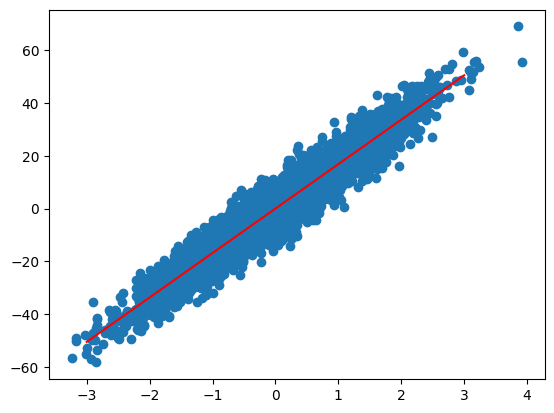

In [8]:
plot_model(X,y,xopt)


## Solving the problem the torch way

In [9]:
def torch_minimize_loss(X, y, eps, delta):
    """
    Minimize f(x) = 1/2 * ||Xw - y||^2 using gradient descent. With gradients
    computed using autograd.
    """
    w = torch.rand(X.shape[1], dtype=torch.float64)

    grad= torch.ones(w.shape, dtype=torch.float64)  # inizializza il gradiente
    while torch.norm(grad) > delta:
        w.requires_grad_(True)  # abilita il calcolo del gradiente per w
        loss = 0.5 * torch.norm(X @ w - y)**2  # calcola la loss

        with torch.no_grad():
            loss.backward() #calcola il gradiente della loss rispetto a w
            grad = w.grad  # ottieni il gradiente calcolato

            w = w - eps * grad  # aggiorna w sottraendo il gradiente moltiplicato per il learning rate eps
    return w.detach().numpy()  # ritorna w come array numpy, staccato dal grafo computazionale

wopt = torch_minimize_loss(X, y, 1E-6, 1E-6)


C:\Users\Raffaele\AppData\Local\Temp\ipykernel_103088\3113919875.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  yy = xx @ w


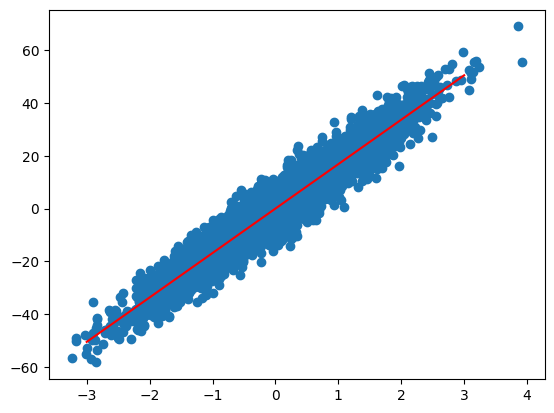

In [10]:

# wopt is a tensor for which we can compute gradients. matplotlib does not
# support plotting tensors that require gradients tracking, so we need to
# detach it from the computation graph and convert it to a numpy array.
plot_model(X,y,wopt)